# 12 — Sidebands Beyond Attribution: Detection, and the Limit of a Confidence Gate

Notebook 11 built shaft-rate sideband features to answer *which race*, and they
worked: race accuracy rose 80.9 % → 87.3 %, and KA15 was attributed correctly
for the first time. It closed with two loose ends, and this notebook takes both.

**The first is a hypothesis worth testing.** Sidebands are *structure* — the
spacing between lines — where every detection feature in this project so far has
been *level*. Level is exactly what notebooks 07 and 08 showed does not transfer
across units: the healthy population splits into two installation groups 2.7–3.8
dB apart, and a foreign baseline can be 100 % wrong on another healthy unit. If
structure travels better than level, sidebands should help **detection**, not
only attribution.

**The second is a caveat this project recorded but never measured.** Notebook 11
left KA30 as the last wrong bearing and noted that a confidence-gated second
look — attribute at 400 N, re-check at 1000 N when the model is unsure — would
plausibly reach 11 of 11, but that on eleven bearings such a rule "cannot be
validated without fitting the test set." That is a claim about method, and it
can be tested rather than asserted.

Both questions reuse notebook 11's feature tables unchanged, so nothing is
re-extracted: one 65 536-sample window per run, 0.977 Hz bins, 25 bearings ×
20 runs, at two radial loads.

In [1]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# n_jobs=-1 makes sklearn emit this from inside its own joblib wrapper, once per
# worker dispatch; with ~180 forest fits below it buries the notebook's output.
warnings.filterwarnings("ignore", message=r".*sklearn\.utils\.parallel\.delayed.*")

OUT = pathlib.Path("../data/processed")
HI, LO = "N15_M07_F10", "N15_M07_F04"
TAG = {HI: "1000 N", LO: "400 N"}

# Built by notebook 11 (65 536-sample window -> 0.977 Hz bins, one row per run).
S = {c: pd.read_csv(OUT / f"pu_{c}_sidebands.csv") for c in (HI, LO)}
LABEL = S[HI].drop_duplicates("Code").set_index("Code")[["Condition", "Domain"]]
HEALTHY = sorted(LABEL.index[LABEL["Domain"] == "healthy"])
REAL = sorted(LABEL.index[LABEL["Domain"] == "real"])
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)

CARRIERS = ["BPFO", "BPFI", "FR"]
SIDEBANDS = ["BPFI_sb1", "BPFO_sb1", "BPFI_sb2", "BPFI_h2_sb1"]
SETS = {
    "carriers": CARRIERS,
    "carriers + harmonics": CARRIERS + ["HARM_BPFO", "HARM_BPFI"],
    "carriers + sidebands": CARRIERS + SIDEBANDS,
    "sidebands only": SIDEBANDS,
    "sideband ratios only": ["SBR_BPFI", "SBR_BPFO", "SBR_diff"],
}

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
RACE_COLOR = {"OR": C_BLUE, "IR": C_ORANGE}


def detect(cond, feats):
    """Leave-one-healthy-bearing-out. Returns the missed-fault rate per real
    bearing and the false-alarm rate on the held-out healthy unit. The model
    trains on healthy + artificial only - it never sees real damage."""
    d = S[cond]
    missed = {b: [] for b in REAL}
    fa = []
    for h in HEALTHY:
        tr = d[((d["Domain"] == "healthy") & (d["Code"] != h)) | (d["Domain"] == "artificial")]
        m = RandomForestClassifier(**RF_KW).fit(tr[feats], tr["Condition"])
        fa.append((m.predict(d[d["Code"] == h][feats]) != "Healthy").mean())
        for b in REAL:
            missed[b].append((m.predict(d[d["Code"] == b][feats]) == "Healthy").mean())
    return pd.Series({b: np.mean(v) for b, v in missed.items()}), np.mean(fa)


print(f"{len(HEALTHY)} healthy + {len(REAL)} real bearings x 20 runs at two loads | "
      f"{len(CARRIERS)} carriers, {len(SIDEBANDS)} sidebands")

6 healthy + 11 real bearings x 20 runs at two loads | 3 carriers, 4 sidebands


## Does structure help detection?

The safety pair, as notebook 09 defined it: **missed-fault rate on real damage**
against **false-alarm rate on an unseen healthy bearing**. Lower-left is better,
and neither axis may be improved by quietly sacrificing the other.

One caution before reading the numbers against notebook 09's. These features
come from a single 65 536-sample window per run, where notebooks 07–10 used
fifteen 16 384-sample windows and a majority vote per recording. The
granularity differs, so the absolute rates here are **not** comparable to
nb09's headline pair — but the comparison *between feature sets*, which is what
this section is about, is like for like.

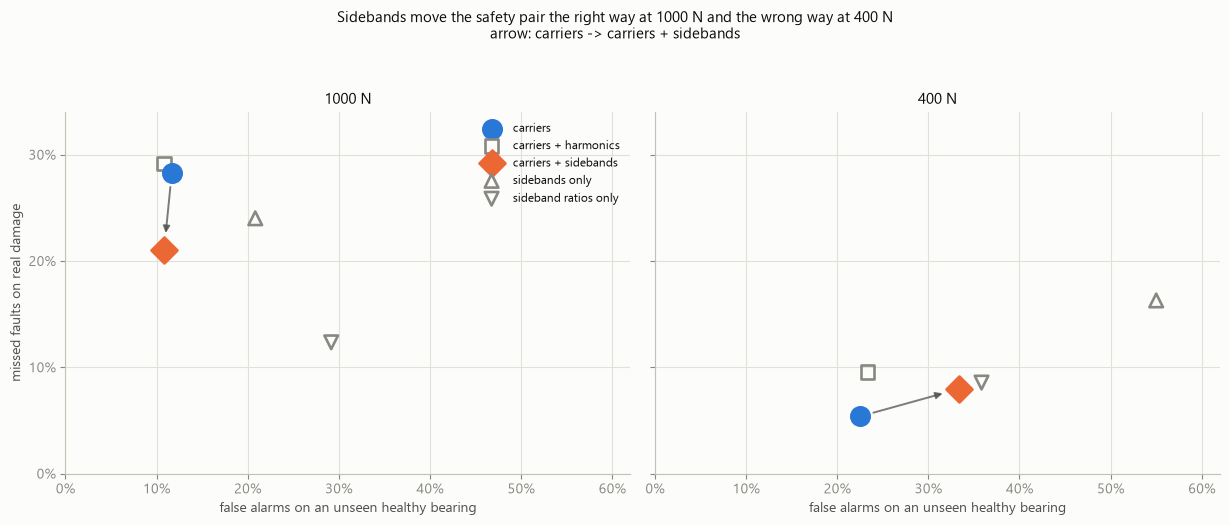

load,features,missed,false_alarm,invisible
1000 N,carriers,28.3%,11.7%,3
1000 N,carriers + harmonics,29.2%,10.8%,3
1000 N,carriers + sidebands,21.1%,10.8%,2
1000 N,sidebands only,24.0%,20.8%,2
1000 N,sideband ratios only,12.3%,29.2%,2
400 N,carriers,5.4%,22.5%,0
400 N,carriers + harmonics,9.5%,23.3%,0
400 N,carriers + sidebands,8.0%,33.3%,0
400 N,sidebands only,16.3%,55.0%,2
400 N,sideband ratios only,8.6%,35.8%,0


In [2]:
rows, per_bearing = [], {}
for cond in (HI, LO):
    for name, feats in SETS.items():
        per, fa = detect(cond, feats)
        per_bearing[(cond, name)] = per
        rows.append(dict(load=TAG[cond], features=name, missed=per.mean(),
                         false_alarm=fa, invisible=int((per > 0.5).sum())))
safety = pd.DataFrame(rows)

MARK = {"carriers": "o", "carriers + harmonics": "s", "carriers + sidebands": "D",
        "sidebands only": "^", "sideband ratios only": "v"}
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.0), sharey=True)
for ax, cond in zip(axes, (HI, LO)):
    sub = safety[safety["load"] == TAG[cond]]
    for _, r in sub.iterrows():
        key = r["features"]
        lead = key in ("carriers", "carriers + sidebands")
        ax.scatter(r["false_alarm"], r["missed"], s=175 if lead else 95,
                   marker=MARK[key], zorder=4 if lead else 3,
                   facecolors=C_ORANGE if key == "carriers + sidebands" else
                              (C_BLUE if key == "carriers" else "none"),
                   edgecolors=C_BLUE if key == "carriers" else
                              (C_ORANGE if key == "carriers + sidebands" else MUTED),
                   linewidths=1.9, label=key)
    a = sub[sub["features"] == "carriers"].iloc[0]
    b = sub[sub["features"] == "carriers + sidebands"].iloc[0]
    ax.annotate("", xy=(b["false_alarm"], b["missed"]), xytext=(a["false_alarm"], a["missed"]),
                arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.4,
                                shrinkA=10, shrinkB=12, alpha=0.75))
    ax.set_xlim(0, 0.62)
    ax.set_xticks([0, .1, .2, .3, .4, .5, .6],
                  ["0%", "10%", "20%", "30%", "40%", "50%", "60%"])
    ax.set_xlabel("false alarms on an unseen healthy bearing")
    ax.set_title(TAG[cond], fontsize=11)
axes[0].set_ylim(0, 0.34)
axes[0].set_yticks([0, .1, .2, .3], ["0%", "10%", "20%", "30%"])
axes[0].set_ylabel("missed faults on real damage")
axes[0].legend(fontsize=8.5, loc="upper right")
fig.suptitle("Sidebands move the safety pair the right way at 1000 N and the wrong way at 400 N\n"
             "arrow: carriers -> carriers + sidebands", fontsize=11, y=1.04)
plt.tight_layout()
plt.show()

safety.style.format({"missed": "{:.1%}", "false_alarm": "{:.1%}"}).hide(axis="index")

The hypothesis survives, but only where it was needed.

**At 1000 N both axes improve at once** — missed faults 28.3 % → 21.1 % and
false alarms 11.7 % → 10.8 %. That is the rare case in this project where a
change is not a trade: notebook 07's anomaly channel bought 1.7 points of
missed fault for 0.8 points of false alarm, and notebook 09's operating-point
move bought detection at the cost of diagnosis. Here nothing is paid.

**At 400 N the same features make things worse on both axes** — 5.4 % → 8.0 %
missed and 22.5 % → 33.3 % false alarms. So the honest statement is not
"sidebands help detection"; it is that they help **where detection is hard**,
and add noise where the carriers already separate cleanly.

The `sideband ratios only` row repeats notebook 11's lesson in a new place.
Those three features give the *lowest* missed-fault rate at 1000 N of anything
tested (12.3 %) while nearly tripling false alarms to 29.2 %. As in nb11, the
ratio encoding is not a neutral re-expression of the same physics — dividing by
a carrier that is itself moving produces a feature that fires readily on
anything, damaged or not.

Which bearings actually moved is the more useful question.

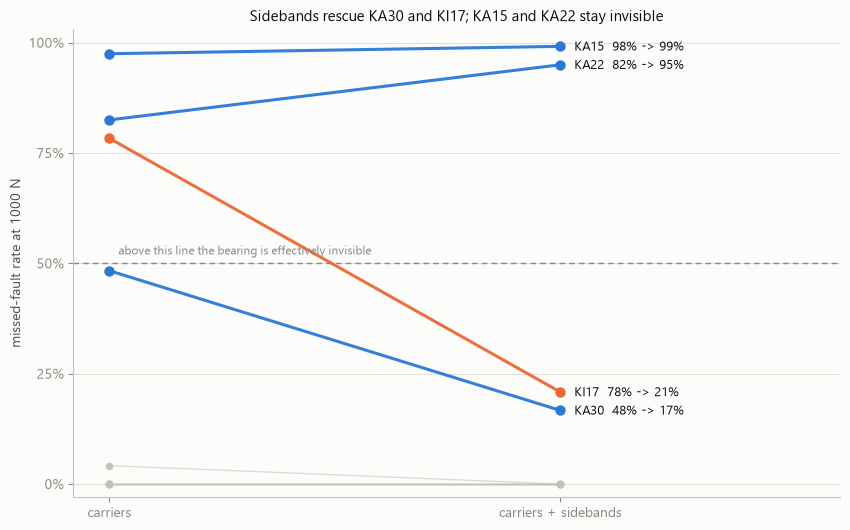

,carriers,carriers + sidebands,Condition,change
KI17,78.3%,20.8%,IR,-57.5%
KA30,48.3%,16.7%,OR,-31.7%
KI16,4.2%,0.0%,IR,-4.2%
KA04,0.0%,0.0%,OR,+0.0%
KI04,0.0%,0.0%,IR,+0.0%
KI14,0.0%,0.0%,IR,+0.0%
KI18,0.0%,0.0%,IR,+0.0%
KA16,0.0%,0.0%,OR,+0.0%
KI21,0.0%,0.0%,IR,+0.0%
KA15,97.5%,99.2%,OR,+1.7%


In [3]:
a = per_bearing[(HI, "carriers")]
b = per_bearing[(HI, "carriers + sidebands")]
order = a.sort_values(ascending=False).index
WATCH = {"KA30", "KI17", "KA15", "KA22"}

fig, ax = plt.subplots(figsize=(8.6, 5.4))
for i, code_ in enumerate(order):
    y0, y1 = a[code_], b[code_]
    race = LABEL.loc[code_, "Condition"]
    hot = code_ in WATCH
    ax.plot([0, 1], [y0, y1], color=RACE_COLOR[race] if hot else BASE,
            lw=2.2 if hot else 1.0, alpha=0.95 if hot else 0.55, zorder=3 if hot else 2)
    ax.scatter([0, 1], [y0, y1], s=42 if hot else 20, zorder=4,
               color=RACE_COLOR[race] if hot else BASE)
    if hot:
        ax.annotate(f"{code_}  {y0:.0%} -> {y1:.0%}", (1, y1), textcoords="offset points",
                    xytext=(10, -3), fontsize=9, color=INK)
ax.axhline(0.5, color=MUTED, lw=1, ls=(0, (4, 3)))
ax.text(0.02, 0.52, "above this line the bearing is effectively invisible",
        fontsize=8.5, color=MUTED)
ax.set_xlim(-0.08, 1.62)
ax.set_xticks([0, 1], ["carriers", "carriers + sidebands"])
ax.set_ylim(-0.03, 1.03)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_ylabel("missed-fault rate at 1000 N")
ax.set_title("Sidebands rescue KA30 and KI17; KA15 and KA22 stay invisible", fontsize=11)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

moved = pd.DataFrame({"carriers": a, "carriers + sidebands": b}).join(LABEL["Condition"])
moved["change"] = moved["carriers + sidebands"] - moved["carriers"]
moved.sort_values("change").style.format({"carriers": "{:.1%}",
                                          "carriers + sidebands": "{:.1%}",
                                          "change": "{:+.1%}"})

The average hides the shape of the win. Seven of the eleven bearings were
already detected essentially always and stay there; the gain is concentrated in
two units:

- **KI17** — 78.3 % → 20.8 % missed. Notebook 06 diagnosed KI17 as the bearing
  that needed *real inner-race training data* to be seen. It does not: it needed
  a feature that describes inner-race modulation, which artificial damage can
  teach.
- **KA30** — 48.3 % → 16.7 % missed. Notebook 06 had grouped KA30 with KA15 as
  "indentation damage, physically silent at BPFO". Half of that grouping is
  wrong. KA30 is not silent, it was simply not being listened to in the right
  place.

**KA15 and KA22 are not rescued, and KA22 is made distinctly worse.** KA15
barely moves (97.5 % → 99.2 % missed), but KA22 goes from 82.5 % to **95.0 %** —
the sidebands cost it 12.5 points. Notebook 06's root cause for both stands:
KA15's damage produces no BPFO line to put sidebands around, and KA22's energy
sits at an off-frequency, non-tracking resonance that no bearing-geometry
feature will find. For KA22 the new features are not merely useless but
actively harmful, because they add variance around a fault frequency where
there is no signal to find.

So sidebands are not a general-purpose rescue. They recover bearings whose
fault frequency is **present but weak**, and they penalise bearings whose fault
energy is somewhere else entirely.

That is worth stating as a rule: **detectable-but-quiet is a feature problem;
absent-from-the-fault-frequency is not.**

## Is it one sideband, or the set?

Four sideband features went in together. Before claiming the structure argument
is what did the work, it is worth checking whether a single one carries the
gain — in particular `BPFI_sb2`, which notebook 11 flagged as suspect: on this
geometry BPFI − 2·fr sits 3.5 Hz from BPFO, inside the ±3 Hz picking window, so
it is partly a second, differently-measured BPFO. If that one feature explains
the improvement, the honest description is "a better BPFO estimate", not
"sideband structure".

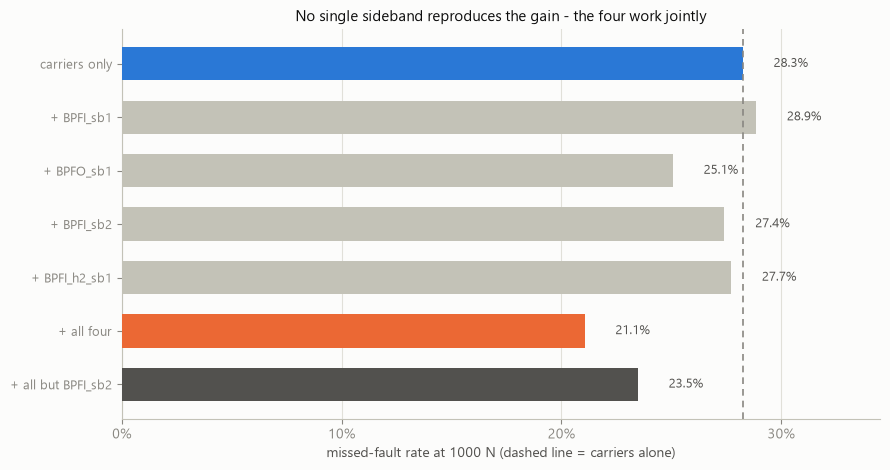

features,missed,false_alarm,KA30,KI17
carriers only,28.3%,11.7%,48.3%,78.3%
+ BPFI_sb1,28.9%,10.8%,48.3%,80.8%
+ BPFO_sb1,25.1%,11.7%,46.7%,45.8%
+ BPFI_sb2,27.4%,10.8%,39.2%,80.0%
+ BPFI_h2_sb1,27.7%,9.2%,45.0%,75.8%
+ all four,21.1%,10.8%,16.7%,20.8%
+ all but BPFI_sb2,23.5%,11.7%,25.8%,36.7%


In [4]:
ABL = {"carriers only": CARRIERS}
for s in SIDEBANDS:
    ABL[f"+ {s}"] = CARRIERS + [s]
ABL["+ all four"] = CARRIERS + SIDEBANDS
ABL["+ all but BPFI_sb2"] = CARRIERS + [s for s in SIDEBANDS if s != "BPFI_sb2"]

abl = []
for name, feats in ABL.items():
    per, fa = detect(HI, feats)
    abl.append(dict(features=name, missed=per.mean(), false_alarm=fa,
                    KA30=per["KA30"], KI17=per["KI17"]))
abl = pd.DataFrame(abl)

fig, ax = plt.subplots(figsize=(9.0, 4.8))
base_v = abl.loc[abl["features"] == "carriers only", "missed"].iloc[0]
BAR = {"carriers only": C_BLUE, "+ all four": C_ORANGE, "+ all but BPFI_sb2": INK2}
for i, r in abl.iterrows():
    ax.barh(i, r["missed"], height=0.62, zorder=3,
            color=BAR.get(r["features"], BASE))
    ax.text(r["missed"] + 0.014, i, f"{r['missed']:.1%}", va="center",
            fontsize=9, color=INK2, zorder=6)
ax.axvline(base_v, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=4)
ax.set_yticks(range(len(abl)), abl["features"], fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 0.345)
ax.set_xticks([0, .1, .2, .3], ["0%", "10%", "20%", "30%"])
ax.set_xlabel("missed-fault rate at 1000 N (dashed line = carriers alone)")
ax.set_title("No single sideband reproduces the gain - the four work jointly", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

abl.style.format({"missed": "{:.1%}", "false_alarm": "{:.1%}",
                  "KA30": "{:.1%}", "KI17": "{:.1%}"}).hide(axis="index")

**The suspicion was wrong, and the ablation says so clearly.** Every sideband
added on its own buys at most 3 points (`BPFO_sb1`, 28.3 % → 25.1 %); `BPFI_sb2`
alone buys one. Only all four together reach 21.1 %. And dropping the suspect
feature entirely still gets 23.5 % — most of the gain survives without it.

So the improvement is a **joint** effect, which is what the structure argument
predicts: a sideband pattern is a relationship among several lines, and no
single line carries it. The BPFO-leakage caveat on `BPFI_sb2` remains true as a
measurement note, but it is not the explanation for the result.

## Why the same features hurt at 400 N

The features that help at high load hurt at low load, and the reason is visible
in the healthy population rather than the damaged one.

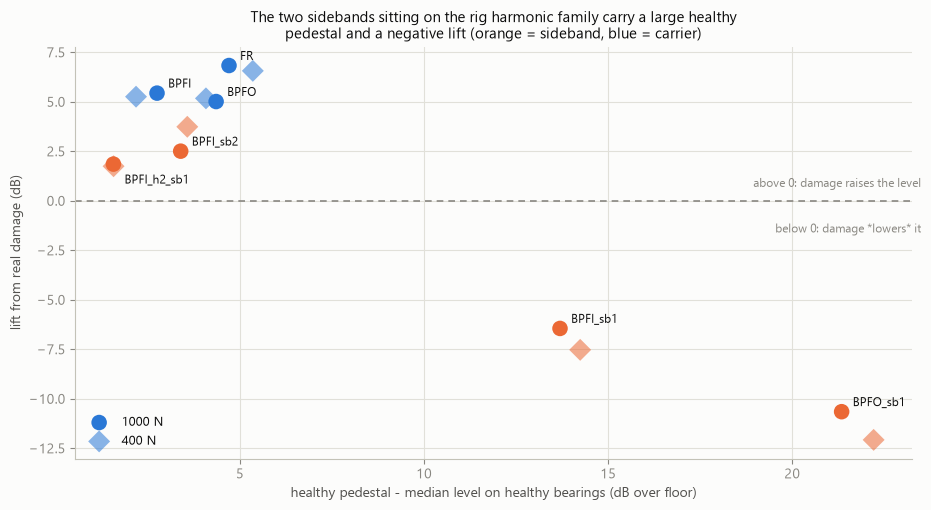

healthy_pedestal        unit_spread          lift       
load                  1000 N  400 N      1000 N  400 N 1000 N  400 N
feature                                                             
BPFI                    2.75   2.18        3.46   2.43   5.44   5.26
BPFI_h2_sb1             1.56   1.57        1.87   1.30   1.85   1.75
BPFI_sb1               13.69  14.24        9.31  10.08  -6.45  -7.53
BPFI_sb2                3.39   3.57        2.21   3.29   2.51   3.74
BPFO                    4.35   4.07        4.82   7.89   5.01   5.18
BPFO_sb1               21.34  22.21       16.08  15.16 -10.65 -12.07
FR                      4.70   5.35        5.44   4.13   6.83   6.56

In [5]:
FEATS = CARRIERS + SIDEBANDS
rows = []
for cond in (HI, LO):
    d = S[cond]
    for f in FEATS:
        h = d[d["Domain"] == "healthy"].groupby("Code")[f].median()
        r = d[d["Domain"] == "real"].groupby("Code")[f].median()
        rows.append(dict(load=TAG[cond], feature=f, healthy_pedestal=h.median(),
                         unit_spread=h.max() - h.min(), lift=r.median() - h.median()))
ped = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.4, 5.2))
for cond, mk, alpha in ((HI, "o", 1.0), (LO, "D", 0.55)):
    sub = ped[ped["load"] == TAG[cond]]
    ax.scatter(sub["healthy_pedestal"], sub["lift"], s=125, marker=mk, alpha=alpha,
               facecolors=[C_ORANGE if f in SIDEBANDS else C_BLUE for f in sub["feature"]],
               edgecolors="none", zorder=3, label=TAG[cond])
LBL = {"BPFI_h2_sb1": (8, -14)}          # else it collides with BPFI_sb2
for _, r in ped[ped["load"] == TAG[HI]].iterrows():
    ax.annotate(r["feature"], (r["healthy_pedestal"], r["lift"]), textcoords="offset points",
                xytext=LBL.get(r["feature"], (8, 4)), fontsize=8.5, color=INK)
ax.axhline(0, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax.text(23.5, 0.7, "above 0: damage raises the level", fontsize=8.5, color=MUTED, ha="right")
ax.text(23.5, -1.6, "below 0: damage *lowers* it", fontsize=8.5, color=MUTED, ha="right")
ax.set_xlabel("healthy pedestal - median level on healthy bearings (dB over floor)")
ax.set_ylabel("lift from real damage (dB)")
ax.set_title("The two sidebands sitting on the rig harmonic family carry a large healthy\n"
             "pedestal and a negative lift (orange = sideband, blue = carrier)", fontsize=11)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

ped.pivot(index="feature", columns="load",
          values=["healthy_pedestal", "unit_spread", "lift"]).round(2)

This is the mechanism, and it is a measurement artefact rather than physics.

`BPFO_sb1` sits at **21.3 dB on healthy bearings** and `BPFI_sb1` at 13.7 dB,
against 2.8–4.7 dB for the carriers. Both then show a *negative* lift on real
damage: −10.7 dB and −6.5 dB. Damage makes them go **down**.

Two things are stacked here. First, the placement: with BPFO at 3.071·fr and
BPFI at 4.929·fr, the ±1·fr sidebands land at orders 2.07, 4.07, 3.93 and 5.93
— and notebook 07 identified a rig harmonic family at roughly orders 2.1, 4.2
and 6.5 that has nothing to do with the bearing. `BPFO_sb1` puts *both* of its
picking windows on that family, which is why its healthy pedestal is the
highest of any feature here.

Second, the normalisation. These levels are dB over the per-window 10–400 Hz
median floor. Real damage raises that floor, because impulsive contact adds
broadband energy. A rig line of fixed absolute size therefore *falls* in dB
when the bearing degrades. So `BPFO_sb1` is behaving, in part, as an inverted
measure of floor elevation.

That it still helps is not a contradiction — an inverted floor gauge is real
information, and the classifier is free to use it. But it does mean the 1000 N
gain should not be reported as "the load-zone sideband physics works for
detection". It is partly that and partly a rig-contamination channel, and on a
different rig the second half would not reproduce. **Sideband placement has to
be checked against the machine's own harmonic family before these features are
trusted**, which is the generalisation of the caveat notebook 11 raised for
`BPFI_sb2` alone.

It also explains the 400 N reversal. The unit-to-unit spread of `BPFO_sb1`
across healthy bearings is 15–16 dB at both loads, so these features carry a
large, unit-specific pedestal. At 1000 N, where KA30 and KI17 are otherwise
nearly invisible, that cost is worth paying. At 400 N the carriers already
separate real damage cleanly, so the pedestal contributes variance and nothing
else — and false alarms rise from 22.5 % to 33.3 %.

## The anomaly channel

The classifier is only half of the detection story. Notebook 07 added a
parallel channel that never sees a fault at all: fit a robust per-feature median
and MAD on healthy units, score anything that exceeds it. That channel is where
the transfer question bites hardest, because it is built entirely from healthy
data and must generalise to a healthy bearing it has not met.

Same protocol as nb07, with the threshold taken from the *training* healthy
bearings at the 99th percentile, so the reported false-alarm rate comes from a
unit that was never in the fit.

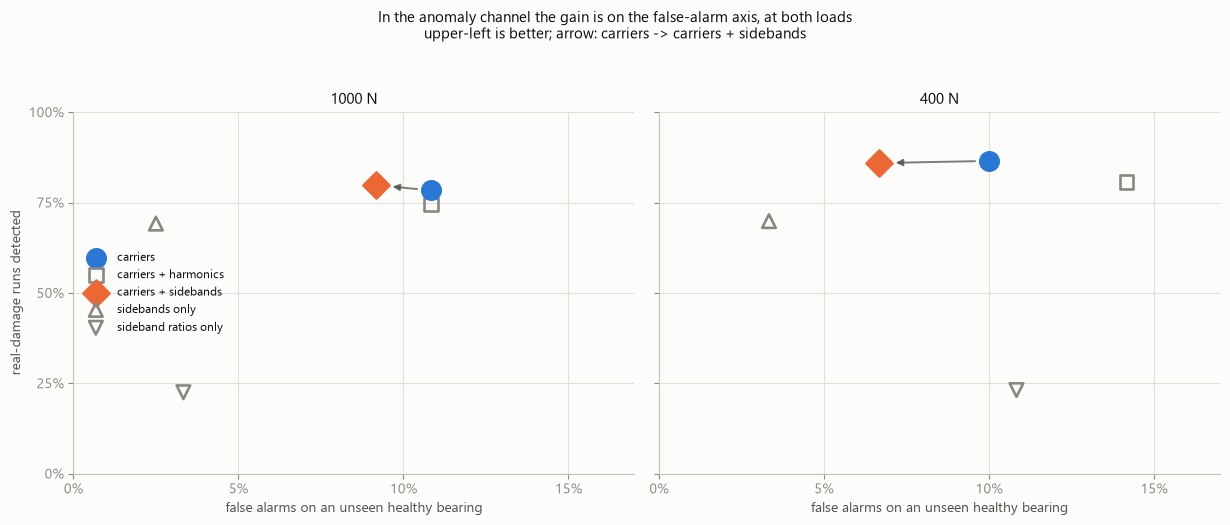

load,features,detected,false_alarm,missed_bearings
1000 N,carriers,78.3%,10.8%,3
1000 N,carriers + harmonics,74.5%,10.8%,3
1000 N,carriers + sidebands,79.8%,9.2%,2
1000 N,sidebands only,69.2%,2.5%,4
1000 N,sideband ratios only,22.5%,3.3%,8
400 N,carriers,86.5%,10.0%,2
400 N,carriers + harmonics,80.7%,14.2%,2
400 N,carriers + sidebands,85.9%,6.7%,2
400 N,sidebands only,69.8%,3.3%,3
400 N,sideband ratios only,23.1%,10.8%,9


In [6]:
class Exceedance:
    """Robust per-feature z over the healthy baseline, max-pooled (notebook 07)."""

    def fit(self, X):
        self.med = np.median(X, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(X - self.med), axis=0), 0.1)
        return self

    def score(self, X):
        return ((X - self.med) / self.mad).max(axis=1)


def anomaly(cond, feats, fpr=0.01):
    """Leave-one-healthy-out. Threshold from TRAIN healthy only, so the
    false-alarm number is measured on a bearing the baseline never saw."""
    d = S[cond]
    det, fa = {b: [] for b in REAL}, []
    for h in HEALTHY:
        tr = d[(d["Domain"] == "healthy") & (d["Code"] != h)]
        m = Exceedance().fit(tr[feats].to_numpy())
        thr = np.quantile(m.score(tr[feats].to_numpy()), 1 - fpr)
        fa.append((m.score(d[d["Code"] == h][feats].to_numpy()) > thr).mean())
        for b in REAL:
            det[b].append((m.score(d[d["Code"] == b][feats].to_numpy()) > thr).mean())
    return pd.Series({b: np.mean(v) for b, v in det.items()}), np.mean(fa)


arows = []
for cond in (HI, LO):
    for name, feats in SETS.items():
        det, fa = anomaly(cond, feats)
        arows.append(dict(load=TAG[cond], features=name, detected=det.mean(),
                          false_alarm=fa, missed_bearings=int((det < 0.5).sum())))
anom = pd.DataFrame(arows)

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.0), sharey=True)
for ax, cond in zip(axes, (HI, LO)):
    sub = anom[anom["load"] == TAG[cond]]
    for _, r in sub.iterrows():
        key = r["features"]
        lead = key in ("carriers", "carriers + sidebands")
        ax.scatter(r["false_alarm"], r["detected"], s=175 if lead else 95,
                   marker=MARK[key], zorder=4 if lead else 3,
                   facecolors=C_ORANGE if key == "carriers + sidebands" else
                              (C_BLUE if key == "carriers" else "none"),
                   edgecolors=C_BLUE if key == "carriers" else
                              (C_ORANGE if key == "carriers + sidebands" else MUTED),
                   linewidths=1.9, label=key)
    a = sub[sub["features"] == "carriers"].iloc[0]
    b = sub[sub["features"] == "carriers + sidebands"].iloc[0]
    ax.annotate("", xy=(b["false_alarm"], b["detected"]), xytext=(a["false_alarm"], a["detected"]),
                arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.4,
                                shrinkA=10, shrinkB=12, alpha=0.75))
    ax.set_xlim(0, 0.17)
    ax.set_xticks([0, .05, .10, .15], ["0%", "5%", "10%", "15%"])
    ax.set_xlabel("false alarms on an unseen healthy bearing")
    ax.set_title(TAG[cond], fontsize=11)
axes[0].set_ylim(0, 1.0)
axes[0].set_yticks([0, .25, .5, .75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
axes[0].set_ylabel("real-damage runs detected")
axes[0].legend(fontsize=8.5, loc="center left")
fig.suptitle("In the anomaly channel the gain is on the false-alarm axis, at both loads\n"
             "upper-left is better; arrow: carriers -> carriers + sidebands",
             fontsize=11, y=1.04)
plt.tight_layout()
plt.show()

anom.style.format({"detected": "{:.1%}", "false_alarm": "{:.1%}"}).hide(axis="index")

Here the hypothesis lands more cleanly than it did for the classifier, because
this channel improves at **both** loads and the gain is on the axis that
matters for a healthy-only baseline:

- **1000 N** — false alarms 10.8 % → 9.2 % *and* detection 78.3 % → 79.8 %.
- **400 N** — false alarms 10.0 % → **6.7 %**, a third lower, at essentially
  unchanged detection (86.5 % → 85.9 %).

So at 400 N the sidebands hurt the classifier and help the anomaly channel,
using the same features on the same rows. The difference is what each one is
asked to do. The classifier must place a boundary between healthy and *damaged*
units, so a large unit-specific pedestal is variance in the way. The anomaly
channel only has to notice that a unit has departed from a healthy population,
and for that a feature with a stable pedestal per unit is useful even if it
never responds to damage in the intended direction.

`sidebands only` is the sharpest version of this: false alarms drop to 2.5–3.3 %,
the lowest of any configuration in this notebook, but three to four of eleven
bearings go undetected (four at 1000 N, three at 400 N). Structure alone is the most *specific* channel and the least
*sensitive* one — which is a reasonable description of what a second opinion
should be.

## KA30, and a confidence gate that only works if you already know the answer

Now the second loose end. Notebook 11 ended at 10 of 11 bearings attributed
correctly, with KA30 wrong at 400 N (45 %) but right at 1000 N (90 %) — a
disagreement notebook 10 had already documented. The obvious move is a gate:
attribute at 400 N, and when the model is unsure, take the 1000 N answer
instead.

"Unsure" is the random forest's own vote share. Threshold 0 never defers, which
is nb11's 400 N result; threshold above 1 always defers, which is the pure
1000 N result. What matters is whether anything in between beats both, **and
whether that threshold could have been chosen without knowing the answer.**

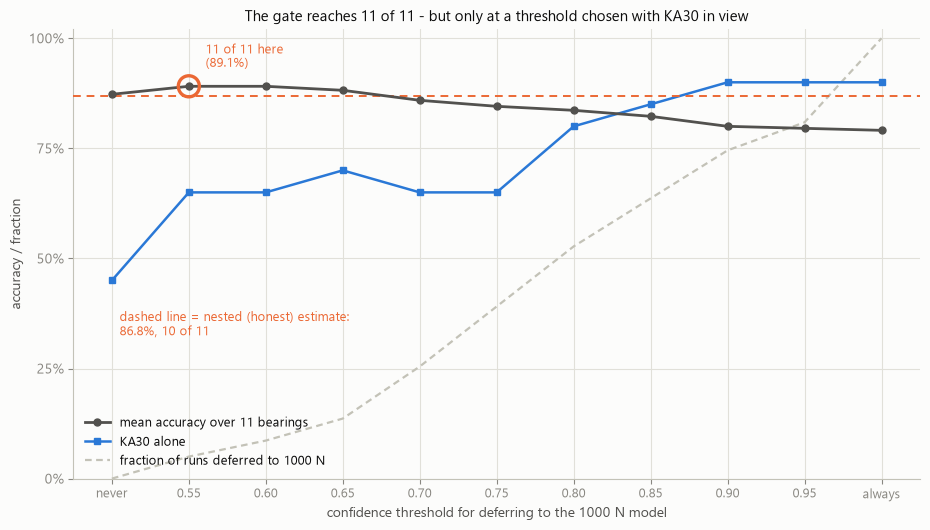

nested leave-one-real-bearing-out: 86.8% mean, 10 of 11 bearings right
thresholds picked per fold: KA04=0.55, KA15=0.60, KA16=0.55, KA22=0.55, KA30=never, KI04=0.55, KI14=0.55, KI16=0.60, KI17=0.55, KI18=0.55, KI21=0.55


threshold,mean_accuracy,bearings_right,deferred,KA30
0.00,87.3%,10,0.0%,45.0%
0.55,89.1%,11,5.0%,65.0%
0.60,89.1%,11,8.6%,65.0%
0.65,88.2%,10,13.6%,70.0%
0.70,85.9%,10,25.5%,65.0%
0.75,84.5%,10,39.1%,65.0%
0.80,83.6%,9,52.7%,80.0%
0.85,82.3%,9,63.6%,85.0%
0.90,80.0%,8,74.5%,90.0%
0.95,79.5%,8,80.9%,90.0%


In [7]:
ATTR = CARRIERS + SIDEBANDS       # nb11's winning attribution set


def attribution_model(cond):
    """Trained on artificial damage only, as in notebook 11."""
    d = S[cond]
    tr = d[d["Domain"] == "artificial"]
    return RandomForestClassifier(**RF_KW).fit(tr[ATTR], tr["Condition"])


M = {c: attribution_model(c) for c in (HI, LO)}


def runs(cond, b):
    return S[cond][S[cond]["Code"] == b].sort_values("Run")


def gated(thr):
    """Attribute at 400 N; where the 400 N model's vote share is below thr,
    take the 1000 N model's answer for the same run instead."""
    acc, deferred = {}, {}
    for b in REAL:
        lo, hi = runs(LO, b), runs(HI, b)
        p = M[LO].predict_proba(lo[ATTR])
        pred = M[LO].classes_[p.argmax(axis=1)].copy()
        unsure = p.max(axis=1) < thr
        if unsure.any():
            pred[unsure] = M[HI].predict(hi[ATTR][unsure])
        acc[b] = (pred == LABEL.loc[b, "Condition"]).mean()
        deferred[b] = unsure.mean()
    return pd.Series(acc), pd.Series(deferred)


GRID = [0.0, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.01]
per_thr, sweep = {}, []
for thr in GRID:
    acc, deferred = gated(thr)
    per_thr[thr] = acc
    sweep.append(dict(threshold=thr, mean_accuracy=acc.mean(),
                      bearings_right=int((acc > 0.5).sum()),
                      deferred=deferred.mean(), KA30=acc["KA30"]))
sweep = pd.DataFrame(sweep)

# Nested check: pick the threshold on ten bearings, score it on the eleventh.
nested, picks = [], []
for held in REAL:
    others = [b for b in REAL if b != held]
    best = max(GRID, key=lambda th: np.mean([per_thr[th][b] for b in others]))
    picks.append(best)
    nested.append(per_thr[best][held])
nested_mean = float(np.mean(nested))
nested_right = int(np.sum(np.array(nested) > 0.5))

fig, ax = plt.subplots(figsize=(9.4, 5.4))
x = np.arange(len(GRID))
ax.plot(x, sweep["mean_accuracy"], color=INK2, lw=2.0, marker="o", ms=5, zorder=4,
        label="mean accuracy over 11 bearings")
ax.plot(x, sweep["KA30"], color=C_BLUE, lw=1.8, marker="s", ms=4.5, zorder=3,
        label="KA30 alone")
ax.plot(x, sweep["deferred"], color=BASE, lw=1.6, ls=(0, (3, 2)), zorder=2,
        label="fraction of runs deferred to 1000 N")
best_i = int(sweep["bearings_right"].idxmax())
ax.scatter([best_i], [sweep.loc[best_i, "mean_accuracy"]], s=230, zorder=5,
           facecolors="none", edgecolors=C_ORANGE, linewidths=2.4)
ax.annotate(f"11 of 11 here\n({sweep.loc[best_i, 'mean_accuracy']:.1%})",
            (best_i, sweep.loc[best_i, "mean_accuracy"]), textcoords="offset points",
            xytext=(12, 14), fontsize=9, color=C_ORANGE)
ax.axhline(nested_mean, color=C_ORANGE, lw=1.4, ls=(0, (4, 3)), zorder=3)
ax.text(0.1, 0.35,
        f"dashed line = nested (honest) estimate:\n{nested_mean:.1%}, {nested_right} of 11",
        fontsize=9, color=C_ORANGE, ha="left", va="center", zorder=6)
ax.set_xticks(x, ["never" if t == 0 else ("always" if t > 1 else f"{t:.2f}") for t in GRID],
              fontsize=9)
ax.set_xlabel("confidence threshold for deferring to the 1000 N model")
ax.set_ylabel("accuracy / fraction")
ax.set_ylim(0, 1.02)
ax.set_yticks([0, .25, .5, .75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("The gate reaches 11 of 11 - but only at a threshold chosen with KA30 in view",
             fontsize=11)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

print(f"nested leave-one-real-bearing-out: {nested_mean:.1%} mean, "
      f"{nested_right} of {len(REAL)} bearings right")
print("thresholds picked per fold:",
      ", ".join(f"{b}={'never' if t == 0 else format(t, '.2f')}" for b, t in zip(REAL, picks)))
sweep.style.format({"mean_accuracy": "{:.1%}", "deferred": "{:.1%}",
                    "KA30": "{:.1%}", "threshold": "{:.2f}"}).hide(axis="index")

**Taken at face value the gate works: 11 of 11 bearings, 89.1 % mean accuracy,
deferring only 5 % of runs.** KA30 goes from 45 % to 65 % and crosses the line,
and nothing else breaks. It is exactly the result notebook 11 predicted.

**The nested check says it is not real.** Choosing the threshold on ten
bearings and scoring the eleventh gives **86.8 % and 10 of 11** — no better than
nb11's plain 400 N model at 87.3 %. The reason is in the per-fold thresholds:
in ten of the eleven folds the gate is chosen and helps, but in the fold where
**KA30 itself is held out, the other ten bearings vote for "never defer"** — and
KA30 is then wrong again.

That is the failure mode in its purest form. KA30 is the *only* bearing that
benefits: deferring costs KA15 (80 % → 75 %) and eventually KA22, so ten
bearings see the gate as a mild liability. The threshold that rescues KA30 can
only be found by someone who already knows KA30's answer. With eleven units,
"the rule that fixes the one remaining failure" and "a rule fitted to the test
set" are the same object, and no amount of care in the sweep separates them.

This is the third time this project has caught the same class of error — after
notebook 05's recording-level CV and notebook 11's feature selection on
artificial damage — and the first time the check was run *before* the number was
reported rather than after. The honest summary of the KA30 question is
therefore: **unresolved, and unresolvable on this benchmark.**

## What this changes

1. **Sidebands help detection where detection is hard.** At 1000 N both safety-
   pair axes improve at once (28.3 % → 21.1 % missed, 11.7 % → 10.8 % false
   alarms). At 400 N they hurt both. The claim to carry forward is conditional,
   not general.
2. **KI17 and KA30 are recovered, and one of notebook 06's root causes is
   wrong.** KI17 (78.3 % → 20.8 % missed) needed an inner-race *feature*, not
   real inner-race training data. KA30 (48.3 % → 16.7 %) was never silent in the
   way KA15 is, so the KA15/KA30 pairing from nb06 should be split. The same
   features push **KA22 the other way, 82.5 % → 95.0 %**: a feature aimed at a
   fault frequency is a liability on a bearing whose energy is not there.
3. **The structure-over-level hypothesis holds best in the anomaly channel**,
   which is where it was predicted to matter: false alarms fall at both loads,
   by a third at 400 N, at unchanged detection. Sidebands alone give the lowest
   false-alarm rate seen in this project (2.5–3.3 %) at the cost of sensitivity.
4. **Part of the gain is rig contamination, not bearing physics.** `BPFO_sb1`
   places both picking windows on the rig harmonic family, carries a 21 dB
   healthy pedestal, and *falls* when damage raises the noise floor. Sideband
   placement must be checked against each machine's own harmonic family before
   these features transfer.
5. **The KA30 confidence gate is a selection artefact.** It reads 11 of 11 and
   nests to 10 of 11, choosing "never defer" precisely when KA30 is held out.